# 4. Agentic RAG 与框架对比

> AutoGen / CrewAI / LangGraph 三种多 Agent 框架的建模方式对比，以及用 LangGraph `StateGraph` 实现一个可运行的多 Agent RAG 系统。

## 本节内容

| 部分 | 主题 | 类型 |
| --- | --- | --- |
| 4.1 | 同一场景的三种建模方式 | 概念 + 伪代码 |
| 4.2 | 三框架对比与选型 | 对比表 |
| 4.3 | Agentic RAG 多 Agent 实战 | 可运行代码 |
| 4.4 | 总结与练习 | 回顾 + 延伸 |

## 学习目标

- 说清 AutoGen「消息驱动」、CrewAI「任务驱动」、LangGraph「状态驱动」的差异
- 理解 `StateGraph` 中 Node / Edge / State 各自的职责
- 独立搭建「检索 → 精排 → 生成 → 验证 → 路由」的多 Agent 流水线
- 知道何时该加 Quality Gate 与 HITL，而不是一味堆 Agent


## 4.1 同一场景的三种建模方式

> 场景固定：**研究员收集资料 → 写作者成稿 → 审校者把关**。
> 三个框架的区别不在于「能不能做」，而在于**你用什么抽象去描述流程**。

### 心智模型速览

| 框架 | 流程靠什么推进 | 你主要在写什么 | 一句话 |
| --- | --- | --- | --- |
| AutoGen | 多轮消息 | Agent 角色 + 发言顺序 | 谁和谁对话 |
| CrewAI | 任务与 process | Agent + Task + Crew | 谁交付任务 |
| LangGraph | 节点与边 | Node + Edge + State | 当前到哪一步 |

### 示例 4A — AutoGen 风格：角色协作

```python
# pseudo_autogen.py（伪代码）
researcher = Agent(name='Researcher', capability='search_and_extract')
writer     = Agent(name='Writer',     capability='compose_summary')
editor     = Agent(name='Editor',     capability='fact_check_and_edit')

def orchestrate(topic):
    docs  = researcher.run({'task': 'search',    'query': topic})
    draft = writer.run(    {'task': 'write',     'context': docs})
    final = editor.run(    {'task': 'verify_and_edit', 'draft': draft, 'context': docs})
    return final
```

**教学点**：少量代码即可声明 Agent 并跑「角色扮演」式流程；本地可以用小模型或模拟返回值替代真实检索。

### 示例 4B — CrewAI 风格：Orchestrator + Worker 队列

```python
# orchestrator_queue.py（伪代码）
job_id = create_job(topic)
push_queue('retriever', {'job_id': job_id, 'topic': topic})
# retriever worker → 推送 reranker 队列
# reranker worker  → 推送 generator 队列
# generator worker → 结果写回 result db
```

**工程点**：

- 每个队列都可以水平扩容 Worker
- `job_id` 用于聚合同一任务的多段结果
- 需要监控队列长度、任务成功率与 Worker 健康度

### 示例 4C — LangGraph 风格：状态图编排

```python
# agentic_rag_multi.py（伪代码）
top5   = call_agent('reranker',  {'query': q, 'candidates': retrieve(q, top_k=50)})
draft  = call_agent('generator', {'query': q, 'context': top5})
verify = call_agent('verifier',  {'draft': draft, 'context': top5})

if verify['pass']:
    return draft
else:
    send_to_human_review(draft, verify)
```

**实践点**：三个要素——各 Agent 只做一件事、Orchestrator 负责调度、Verifier 充当质量门。

> 📌 4.3 节会把示例 4C 落成一个真正可运行的 LangGraph 程序。


## 4.2 三框架对比与选型

### 总览

| 维度 | AutoGen | CrewAI | LangGraph |
| --- | --- | --- | --- |
| 核心重心 | 对话协作 | 任务编排 | 状态图工作流 |
| 主要抽象 | Agent / Team / Message | Agent / Task / Crew | Node / Edge / State |
| 状态载体 | 消息与团队上下文 | 任务执行上下文 | 显式共享状态 |
| 初学体验 | 最容易起步 | 中等 | 概念更重 |
| 更适合 | 原型、教学 | 自动化流程 | 复杂分支、持久化 |

### 架构维度

| 问题 | AutoGen | CrewAI | LangGraph |
| --- | --- | --- | --- |
| 流程靠什么推进 | 多轮消息 | 任务与 process | 节点与边 |
| 中心关注点 | 谁来对话 | 谁来做任务 | 当前状态是什么 |
| 强项 | 角色协作感 | 任务交付感 | 控制流可视性 |
| 容易失控处 | 对话轮次 | 任务边界 | 图设计复杂度 |

### 工程维度

| 维度 | AutoGen | CrewAI | LangGraph |
| --- | --- | --- | --- |
| 可控性 | 中 | 中高 | 高 |
| 可观测性 | 对话 / trace 友好 | 运行 / 任务友好 | 状态 / 路径友好 |
| 长流程恢复 | 需额外设计 | 取决于外围流程 | 原生支持更好 |
| 学习曲线 | 低 | 中 | 中高 |
| 适合课堂起步 | 很适合 | 适合进阶 | 适合做对比理解 |

### LangGraph 为什么值得单独比较

- 重心是 **graph + state + routing**，做的是显式、可恢复的工作流
- 它不是 AutoGen / CrewAI 的替代品，而是站在更低的抽象层
- 分支多、状态重、需要 checkpoint / HITL 的流程，用图模型最自然
- 代价是概念门槛更高、前期设计成本更大

> 一句话：**消息驱动关注「说了什么」，状态驱动关注「现在到哪一步了」。**

### 选型决策

| 你的目标 | 优先选择 |
| --- | --- |
| 教学原型、角色协作演示 | **AutoGen** |
| 任务编排、交付流程、自动化执行 | **CrewAI** |
| 状态图工作流、审批流、可恢复长流程 | **LangGraph** |
| 不确定 | 先用最简单的抽象，不要一上来堆满多 Agent |

> 先选抽象模型，再选框架名字。常见路线：AutoGen 验证价值 → CrewAI / LangGraph 产品化。


## 4.3 Agentic RAG：多 Agent 协作实战

> 把 RAG 拆成多个专职 Agent，每个只负责一个环节，由 LangGraph `StateGraph` 统一编排。

```mermaid
graph LR
    S([START]) --> R[Retriever<br/>粗检索]
    R --> K[Reranker<br/>LLM 精排]
    K --> G[Generator<br/>生成草稿]
    G --> V{Verifier<br/>质量门}
    V -->|pass| A[Accept]
    V -->|fail / 低置信度| H[Review<br/>HITL]
    A --> E([END])
    H --> E
```

### Agent 职责划分

| 节点 | 角色 | 输入 | 输出 | 用哪个模型 |
| --- | --- | --- | --- | --- |
| `retriever` | 粗检索（召回） | `query` | `candidates` | 无 LLM，关键词匹配 |
| `reranker` | 精排 | `query` + `candidates` | `top_docs` | Haiku（快） |
| `generator` | 生成草稿 | `query` + `top_docs` | `draft_answer` | Sonnet（强） |
| `verifier` | 质量门 | `draft_answer` + `top_docs` | `verify_result` | Haiku（快） |
| `accept` / `review` | 终止分支 | `verify_result` | `final_answer` | 无 LLM |

### 共享状态字段

| 字段 | 类型 | 说明 |
| --- | --- | --- |
| `query` | `str` | 用户问题 |
| `candidates` | `List[str]` | 粗检索候选文档 |
| `top_docs` | `List[str]` | 精排后的文档 |
| `draft_answer` | `str` | 生成器草稿 |
| `verify_result` | `dict` | `{pass, confidence, issues}` |
| `final_answer` | `Optional[str]` | 最终答案（未通过时为 `None`） |
| `needs_review` | `bool` | 是否进入人工审查 |

> 关键约定：每个节点**只返回自己改动的字段**，由 LangGraph 合并进共享状态。


### Step 1 — 环境初始化

从项目根目录的 `.env` 读取 Key，并准备两个量级的模型：

- **Sonnet** — 生成质量优先
- **Haiku** — 精排 / 校验这类轻量任务，快且便宜


In [1]:
import os
import warnings

warnings.filterwarnings('ignore')

from dotenv import load_dotenv

load_dotenv()

OPENROUTER_API_KEY = os.getenv('OPENROUTER_API_KEY')
OPENROUTER_BASE_URL = 'https://openrouter.ai/api/v1'

if not OPENROUTER_API_KEY:
    raise OSError(
        'OPENROUTER_API_KEY 未设置。\n'
        '请前往 https://openrouter.ai 获取 Key，'
        '并在 .env 中添加：OPENROUTER_API_KEY=sk-or-v1-...'
    )

MODEL_SONNET = 'anthropic/claude-sonnet-4-5'   # 推理强，适合生成
MODEL_HAIKU = 'anthropic/claude-haiku-4-5'     # 速度快，适合精排 / 校验

print('✅ 环境变量加载成功')
print(f'   OPENROUTER_API_KEY : {OPENROUTER_API_KEY[:12]}...')
print(f'   Sonnet             : {MODEL_SONNET}')
print(f'   Haiku              : {MODEL_HAIKU}')


✅ 环境变量加载成功
   OPENROUTER_API_KEY : sk-or-v1-ae3...
   Sonnet             : anthropic/claude-sonnet-4-5
   Haiku              : anthropic/claude-haiku-4-5


### Step 2 — 定义共享状态与 LLM 客户端

`TypedDict` 是 LangGraph 推荐的 state 声明方式：类型显式、便于调试。

两个客户端按任务分层使用，避免「所有环节都上最强模型」的成本浪费。


In [2]:
from typing import TypedDict

from langchain_core.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph

# 通过 OpenRouter 初始化 LangChain 客户端（OpenAI 兼容接口）
llm_sonnet = ChatOpenAI(
    model=MODEL_SONNET,
    openai_api_key=OPENROUTER_API_KEY,
    openai_api_base=OPENROUTER_BASE_URL,
    max_tokens=1024,
)

llm_haiku = ChatOpenAI(
    model=MODEL_HAIKU,
    openai_api_key=OPENROUTER_API_KEY,
    openai_api_base=OPENROUTER_BASE_URL,
    max_tokens=512,
)


class AgenticRAGState(TypedDict):
    """图内共享状态。每个节点只返回自己改动的字段。"""

    query: str
    candidates: list[str]
    top_docs: list[str]
    draft_answer: str
    verify_result: dict
    final_answer: str | None
    needs_review: bool


print('✅ LLM 客户端与共享状态定义完成')


✅ LLM 客户端与共享状态定义完成


### Step 3 — Retriever：粗检索（召回优先）

> 真实项目中把这一步换成向量库 / BM25 即可，节点函数签名保持不变。
>
> 教学版用「关键词命中数」打分，目的是让整条流程离线也能跑通。

节点职责：**只做召回，不做判断**，返回 5 条候选交给下游精排。


In [3]:
# 模拟知识库（真实场景替换为向量库检索结果）
KNOWLEDGE_BASE = [
    'AutoGen 是微软开发的多 Agent 框架，支持 GraphFlow、SelectorGroupChat 等多种协作模式。',
    'CrewAI 提供高层级抽象，通过 Agent、Task、Crew 三个核心概念实现多 Agent 协作。',
    'LangGraph 使用有向图表达 Agent 工作流，适合需要循环、分支和状态管理的复杂流程。',
    '多 Agent 系统的常见通信模式包括：同步 RPC、异步消息队列、共享黑板（Blackboard）。',
    'Agentic RAG 将检索过程拆解为：粗检索、精排、生成、验证四个阶段，提升答案质量。',
    'Agent 可观测性工具包括：LangSmith、Arize、Weights & Biases，支持 Trace 记录和性能分析。',
    '多 Agent 系统的常见陷阱：无限循环、过度中心化 Orchestrator、共享状态竞态条件。',
    'Quality Gate（质量门）在关键节点插入验证 Agent，确保输出满足质量标准后才流向下一步。',
    'HITL（人在回路）通过将低置信度结果路由到人工审查，平衡自动化与准确性。',
    'OpenRouter 提供统一的 OpenAI 兼容接口，支持路由到 Claude、GPT、Gemini 等多种模型。',
]


def retriever_node(state: AgenticRAGState) -> dict:
    """粗检索：按关键词命中数打分，返回 top-5 候选。"""
    query = state['query']
    keywords = query.lower().split()

    scored = [
        (sum(1 for kw in keywords if kw in doc.lower()), doc)
        for doc in KNOWLEDGE_BASE
    ]
    candidates = [doc for score, doc in sorted(scored, reverse=True) if score > 0][:5]
    if not candidates:          # 兜底：完全没命中时给默认上下文
        candidates = KNOWLEDGE_BASE[:3]

    print(f'[Retriever] 检索到 {len(candidates)} 条候选')
    return {'candidates': candidates}


### Step 4 — Reranker：LLM 精排

召回靠匹配，排序靠理解。这里让 **Haiku** 从 5 条候选里挑出最相关的 3 条：

- 只要求输出编号，输出极短 → 省 token、好解析
- 解析失败时降级为「取前 3 条」，保证流程不会中断

> 这就是给节点加**防御性兜底**的典型写法。


In [4]:
def reranker_node(state: AgenticRAGState) -> dict:
    """精排：让模型从候选中挑出最相关的 3 条。"""
    query, candidates = state['query'], state['candidates']
    numbered = '\n'.join(f'{i + 1}. {doc}' for i, doc in enumerate(candidates))

    response = llm_haiku.invoke([
        SystemMessage(content='选出与查询最相关的 3 条文档，只输出编号（逗号分隔，如：1,3,5）。'),
        HumanMessage(content=f'查询：{query}\n\n候选：\n{numbered}\n\n最相关编号：'),
    ])

    try:
        indices = [int(x.strip()) - 1 for x in response.content.split(',') if x.strip().isdigit()]
        top_docs = [candidates[i] for i in indices if 0 <= i < len(candidates)]
        if not top_docs:        # 模型没给出有效编号时降级
            top_docs = candidates[:3]
    except Exception:
        top_docs = candidates[:3]

    print(f'[Reranker] 精排保留 {len(top_docs)} 条')
    return {'top_docs': top_docs}


### Step 5 — Generator：生成草稿

这一环是唯一需要「写作能力」的节点，因此用 **Sonnet**。

System Prompt 里有两条硬约束：

1. **只根据参考文档回答** —— 抑制幻觉
2. **200 字以内** —— 控制成本，也方便人工复核


In [5]:
def generator_node(state: AgenticRAGState) -> dict:
    """生成：只依据精排后的文档作答。"""
    context = '\n'.join(f'• {doc}' for doc in state['top_docs'])

    response = llm_sonnet.invoke([
        SystemMessage(content='仅根据参考文档回答问题，200 字以内。'),
        HumanMessage(content=f'参考文档：\n{context}\n\n问题：{state["query"]}'),
    ])

    print(f'[Generator] 生成答案（{len(response.content)} 字）')
    return {'draft_answer': response.content}


### Step 6 — Verifier：质量门（Quality Gate）

这是整个系统里**最值得加的一环**：它不产出内容，只做判断。

- 要求模型输出结构化 JSON：`{"pass", "confidence", "issues"}`
- 解析失败时默认放行（`pass=True, confidence=0.7`），避免误伤
- `issues` 会被后续的 HITL 分支带出去，告诉人工「哪里可疑」


In [6]:
import json
import re


def verifier_node(state: AgenticRAGState) -> dict:
    """校验：答案是否被参考文档支撑，并给出置信度与问题列表。"""
    context = '\n'.join(f'• {doc}' for doc in state['top_docs'])

    response = llm_haiku.invoke([
        SystemMessage(content=(
            '检验答案与参考文档的一致性。'
            '输出 JSON：{"pass": true/false, "confidence": 0.0-1.0, "issues": [...]}'
        )),
        HumanMessage(content=f'参考：\n{context}\n\n答案：\n{state["draft_answer"]}'),
    ])

    default = {'pass': True, 'confidence': 0.7, 'issues': []}
    try:
        match = re.search(r'\{.*\}', response.content, re.DOTALL)
        result = json.loads(match.group()) if match else default
    except Exception:
        result = default

    status = '✅ 通过' if result.get('pass') else '❌ 未通过'
    print(f'[Verifier] {status} (置信度: {result.get("confidence", 0):.2f})')
    return {'verify_result': result}


### Step 7 — Orchestrator：路由与终止分支

只做两件事，但决定了系统的「质量水位」：

- **路由**：`pass` 且 `confidence >= 0.6` → `accept`，否则 → `review`
- **终止**：两个分支都连到 `END`，形成一条「二元出口」

> 阈值 `0.6` 是这套系统最重要的旋钮：调高 → 更多人工介入；调低 → 更自动化但风险更高。


In [7]:
def orchestrator_route(state: AgenticRAGState) -> str:
    """条件边：决定走 accept 还是 review。"""
    result = state.get('verify_result', {})
    passed = result.get('pass', True) and result.get('confidence', 0.7) >= 0.6
    return 'accept' if passed else 'review'


def accept_node(state: AgenticRAGState) -> dict:
    """自动通过：把草稿升级为最终答案。"""
    print('[Orchestrator] ✅ 答案接受')
    return {'final_answer': state['draft_answer'], 'needs_review': False}


def review_node(state: AgenticRAGState) -> dict:
    """低置信度：转人工审查，不输出最终答案。"""
    issues = state.get('verify_result', {}).get('issues', [])
    print(f'[Orchestrator] ⚠️  需要人工审查：{issues}')
    return {'needs_review': True, 'final_answer': None}


### Step 8 — 组装 StateGraph

前面写的都是普通 Python 函数，`StateGraph` 负责把它们连成一张图：

- `add_node` — 注册节点
- `add_edge` — 固定顺序
- `add_conditional_edges` — 按返回值路由，`{'accept': ..., 'review': ...}` 是**路由表**


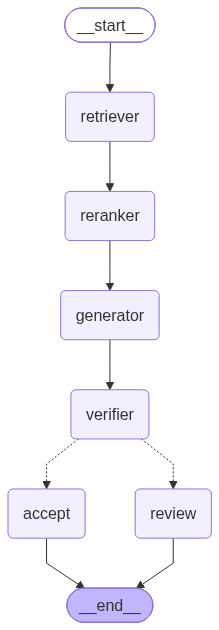

✅ Agentic RAG 图构建完成


In [8]:
rag_builder = StateGraph(AgenticRAGState)

# 注册节点
rag_builder.add_node('retriever', retriever_node)
rag_builder.add_node('reranker', reranker_node)
rag_builder.add_node('generator', generator_node)
rag_builder.add_node('verifier', verifier_node)
rag_builder.add_node('accept', accept_node)
rag_builder.add_node('review', review_node)

# 主链路
rag_builder.add_edge(START, 'retriever')
rag_builder.add_edge('retriever', 'reranker')
rag_builder.add_edge('reranker', 'generator')
rag_builder.add_edge('generator', 'verifier')

# 条件分支：质量门 → 自动通过 / 人工审查
rag_builder.add_conditional_edges(
    'verifier',
    orchestrator_route,
    {'accept': 'accept', 'review': 'review'},
)
rag_builder.add_edge('accept', END)
rag_builder.add_edge('review', END)

agentic_rag = rag_builder.compile()

# 可视化：优先渲染 PNG，失败则退回文字描述
try:
    from IPython.display import Image, display

    display(Image(agentic_rag.get_graph().draw_mermaid_png()))
except Exception:
    print('流程：START → retriever → reranker → generator → verifier → [accept | review] → END')

print('✅ Agentic RAG 图构建完成')


### Step 9 — 运行

初始 state 只需要给出 `query`，其余字段给空值占位；执行过程中各节点会逐步填满。


In [9]:
test_query = 'AutoGen 和 CrewAI 有什么区别，各自适合什么场景？'
print(f'❓ 查询：{test_query}\n' + '─' * 60)

final_state = agentic_rag.invoke({
    'query': test_query,
    'candidates': [],
    'top_docs': [],
    'draft_answer': '',
    'verify_result': {},
    'final_answer': None,
    'needs_review': False,
})

print('─' * 60)
if final_state['final_answer']:
    print(f'\n✅ 最终答案：\n{final_state["final_answer"]}')
else:
    print('\n⚠️  需要人工审查')
    print(f'    草稿：{final_state["draft_answer"][:200]}...')
    print(f'    问题：{final_state["verify_result"].get("issues", [])}')

# 观察状态流转：每个节点只写了属于自己的字段
print('\n📦 最终 state 字段：')
for key, value in final_state.items():
    preview = str(value)
    print(f'   {key:<15}: {preview[:60]}')


❓ 查询：AutoGen 和 CrewAI 有什么区别，各自适合什么场景？
────────────────────────────────────────────────────────────
[Retriever] 检索到 4 条候选
[Reranker] 精排保留 2 条
[Generator] 生成答案（287 字）
[Verifier] ✅ 通过 (置信度: 0.92)
[Orchestrator] ✅ 答案接受
────────────────────────────────────────────────────────────

✅ 最终答案：
根据参考文档，两个框架的主要区别：

**AutoGen（微软开发）**
- 特点：支持多种协作模式（GraphFlow、SelectorGroupChat等）
- 适合场景：需要灵活切换不同协作模式的复杂场景，适合需要精细控制Agent交互流程的应用

**CrewAI**
- 特点：提供高层级抽象，通过Agent、Task、Crew三个核心概念实现协作
- 适合场景：快速构建多Agent系统，概念清晰简单，适合标准化的团队协作场景

**总结**：AutoGen更灵活、可定制性强，适合复杂多变的协作需求；CrewAI更简洁易用，适合快速开发和标准化的团队协作任务。

📦 最终 state 字段：
   query          : AutoGen 和 CrewAI 有什么区别，各自适合什么场景？
   candidates     : ['LangGraph 使用有向图表达 Agent 工作流，适合需要循环、分支和状态管理的复杂流程。', 'CrewAI
   top_docs       : ['CrewAI 提供高层级抽象，通过 Agent、Task、Crew 三个核心概念实现多 Agent 协作。', 'A
   draft_answer   : 根据参考文档，两个框架的主要区别：

**AutoGen（微软开发）**
- 特点：支持多种协作模式（GraphFlow
   verify_result  : {'pass': True, 'confidence': 0.92, 'issues': [{'type': 'mino
   final_answer   : 根据参考文档，两个框架的主要

### Step 10 — 观察与思考

跑完之后，对照输出回答这几个问题：

1. **谁改了哪个字段？** 打印 `[Retriever]` / `[Reranker]` / `[Generator]` / `[Verifier]` 的顺序，就是 graph 的执行路径。
2. **为什么 Verifier 用 Haiku 而不是 Sonnet？** 它只做一致性判断，输入短、要求结构化，用快模型性价比更高。
3. **如果 verifier 判了 fail 会怎样？** `orchestrator_route` 返回 `review`，`final_answer` 为 `None`，`needs_review=True`。
4. **想让它更严格怎么做？** 把阈值从 `0.6` 调高（例如 `0.85`），HITL 比例会明显上升。

> 💡 注意：`review` 分支目前只是「标记需要人工」，真正的暂停 / 恢复需要 LangGraph 的 **checkpointer + `interrupt()`**，见 4.4 练习 2。


## 4.4 总结与练习

### 本节回顾

| 要点 | 结论 |
| --- | --- |
| 三框架差异 | 消息驱动 / 任务驱动 / 状态驱动，是三种组织世界观 |
| LangGraph 的价值 | 控制流显式、状态可追踪、可 checkpoint 恢复 |
| 多 Agent 拆分原则 | 每个 Agent 只做一件事，接口用共享状态约定 |
| 质量保障 | Verifier 质量门 + 阈值路由 + HITL 出口 |
| 成本控制 | 按任务难度选择模型档位，而不是全用最强模型 |

### 练习

1. **换框架重写**：参考 [`04-autogen_实战.ipynb`](04-autogen_实战.ipynb) 的 `GraphFlow`，把这条链路用 AutoGen 重写一遍，对比代码量。
2. **真正的 HITL**：给 `review` 分支加 `MemorySaver` checkpointer + `interrupt()`，实现「暂停 → 人工修改 → 从断点恢复」。
3. **加回退环**：让 `verifier` 失败时带着 `issues` 回到 `generator` 重写，最多重试 2 次（注意加上次数上限，避免无限循环）。
4. **换真实检索**：把 `KNOWLEDGE_BASE` 换成 FAISS / Chroma，`retriever_node` 内部改为向量检索，其余节点不需要改动。
5. **记录 trace**：接入 LangSmith，观察每个节点的输入输出与耗时分布。

### 常见陷阱

- **无限循环** — 回退边一定要有次数上限或终止条件
- **过度中心化 Orchestrator** — 所有决策都塞给它，最后只是「一个大 Agent + 几个空壳」
- **共享状态竞态** — 并行节点写同一字段时，需要明确合并策略
